# k-means Clustering

## Table of contents

[1.) Simple k-means clustering example](#section_1)<br>
[2.) Image segmentation](#section_2)<br>
[3.) 3D point cloud segmentation](#section_3)<br>
[4.) Finding clusters in the apartment data](#section_4)

## Libraries and settings

In [1]:
# Libraries
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

# Current working directory
print('\nCurrent working directory:', os.getcwd())


Current working directory: /home/claude/build/Week_10


## 1.) Simple k-means clustering example
<a id='section_1'></a>

### Create the dataset

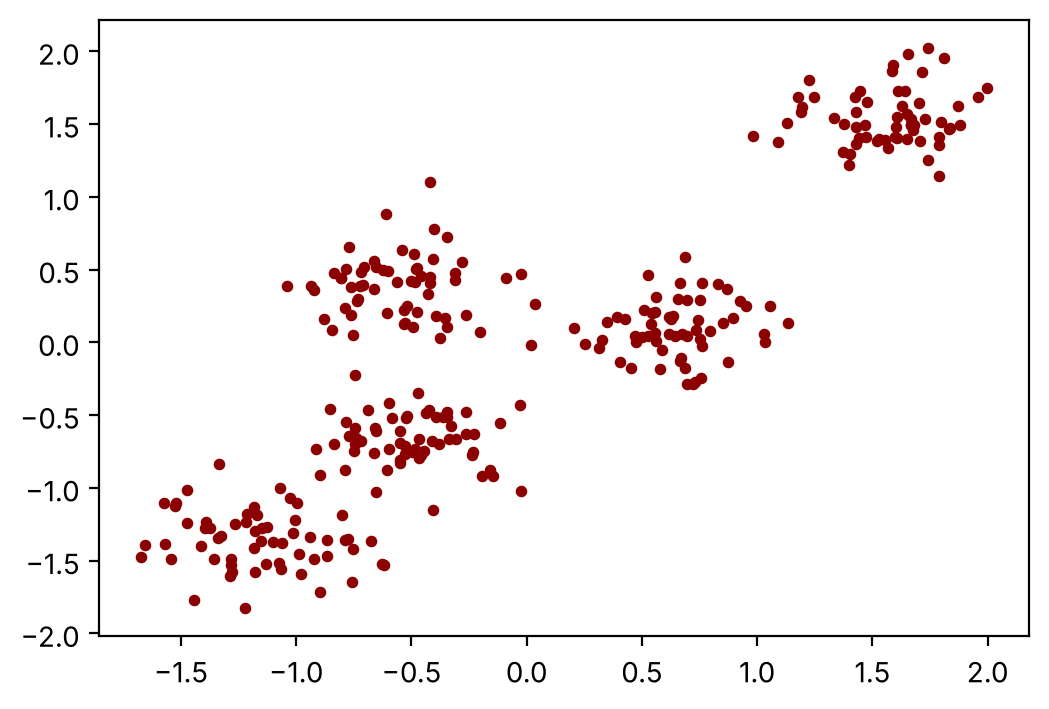

In [2]:
# Create data
centers = [[2,1], [-2,2], [-2,-2], [-4,-5], [5,7]]
X, y = make_blobs(n_samples=300, 
                  centers=centers, 
                  cluster_std=0.8,
                  random_state=42)

# Normalization of the values
X = StandardScaler().fit_transform(X)

# Plot the data
plt.figure(figsize=(6,4))
plt.scatter(X[:,0], X[:,1], s=10, color='darkred')
plt.show()

### Elbow Method showing the optimal k

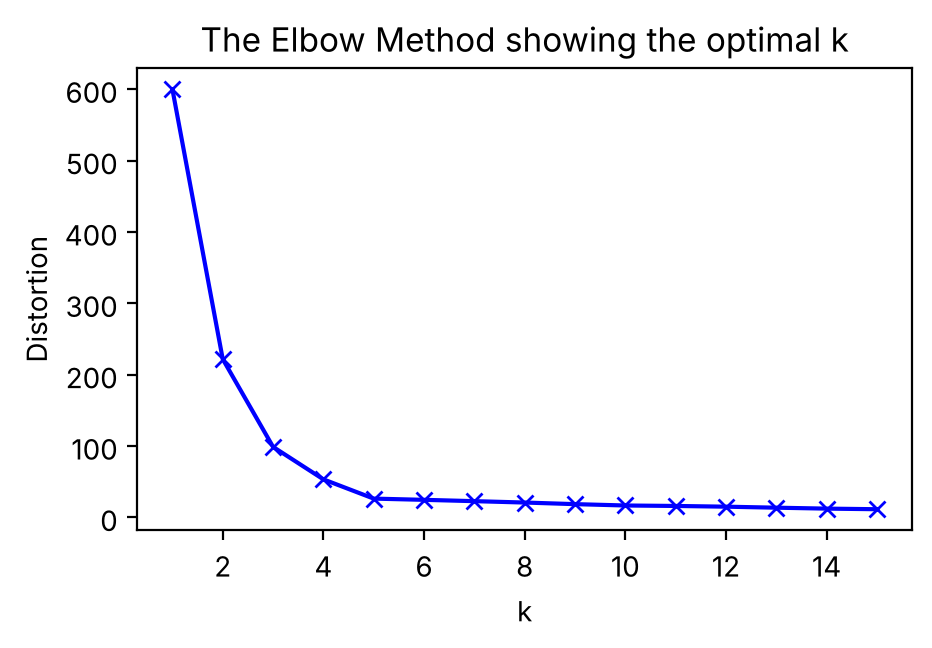

In [3]:
# Sum of squared distances of samples to their closest cluster center
distortions = []

# Range of k's
K = range(1,16,1)

# Loop to find the optimal k
for k in K:
    kmeanModel = KMeans(n_clusters=k)
    kmeanModel.fit(X)
    distortions.append(kmeanModel.inertia_)
    
# Elbow plot
plt.figure(figsize=(5,3))
plt.plot(K, distortions, 'bx-')
plt.xlabel('k')
plt.ylabel('Distortion')
plt.title('The Elbow Method showing the optimal k')

plt.show()

**Aufgabe 1b – Antwort:** Im Ellbogendiagramm fällt die Distortion bis k = 5 stark ab und flacht danach praktisch ab (der "Ellbogen" liegt bei k = 5). Der optimale Wert für dieses Clustering Modell ist daher **k = 5**. Das passt zu den Daten, denn diese wurden mit 5 Zentren erzeugt (`centers` in der Zelle "Create the dataset").

### Perform k-means clustering

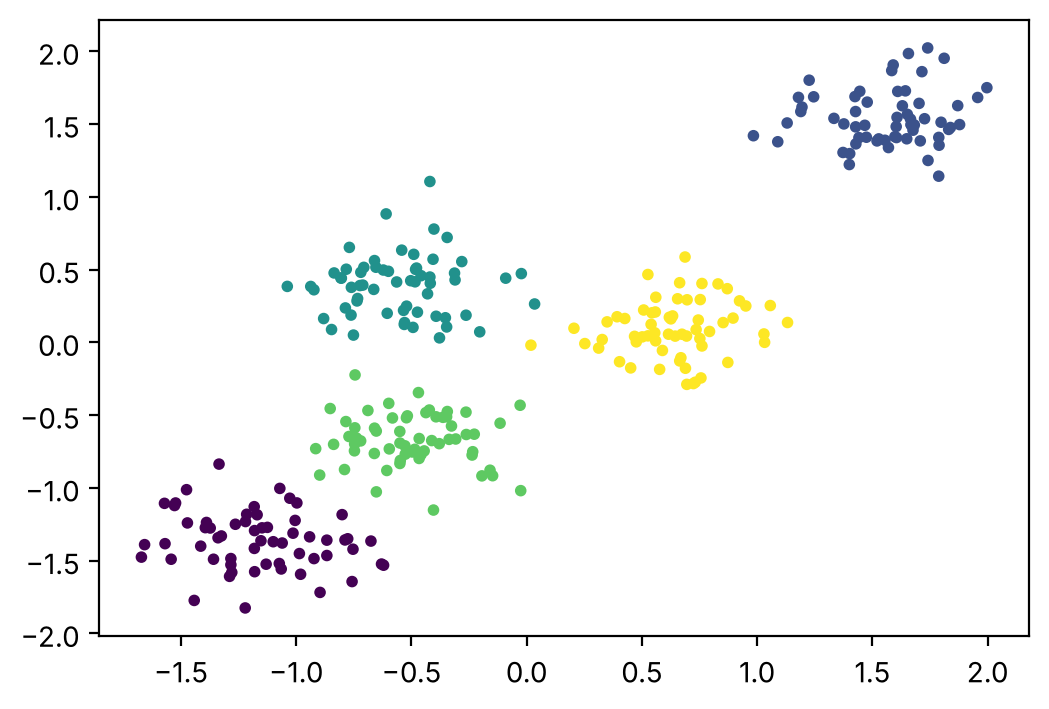

In [4]:
# Number of clusters
k = 5

# k-means clustering
kmeans = KMeans(n_clusters=k, random_state=42).fit(X)

# Predict the values
y2 = kmeans.predict(X)

# Plot the clusters
plt.figure(figsize=(6,4))
plt.scatter(X[:, 0], X[:, 1], c=y2, s=10)
plt.show()

### Get and check the converged cluster centroids

In [5]:
# Print centroids
centroids = kmeans.cluster_centers_
print('Cluster centroids:')
print(centroids, '\n')

# Check the 1st cluster's centroid 'by hand'
clust_00 = X[y2 == 0]
print('The 1st cluster\'s centroid:')
print(f'x = {sum(clust_00[:,0]/len(clust_00[:,0])):.8f}')
print(f'y = {sum(clust_00[:,1]/len(clust_00[:,1])):.8f}')

Cluster centroids:
[[-1.16214999 -1.36217282]
 [ 1.56276666  1.54186443]
 [-0.55467879  0.3889481 ]
 [-0.49867406 -0.67040574]
 [ 0.64167824  0.09023659]] 

The 1st cluster's centroid:
x = -1.16214999
y = -1.36217282


### Get the inertia or 'within-cluster sum-of-squares (WCSS)' of the k-means model

In [6]:
print(f'Within-cluster sum-of-squares: {kmeans.inertia_:.4f}')

Within-cluster sum-of-squares: 26.3487


### Perform Silhouette Analysis
- For examples see:
- https://laid-back-scientist.com/en/k-means
- https://machinelearninggeek.com/evaluating-clustering-methods
- https://medium.com/@favourphilic/how-to-interpret-silhouette-plot-for-k-means-clustering-414e144a17fe

k=2, Silhouette Score: 0.5325


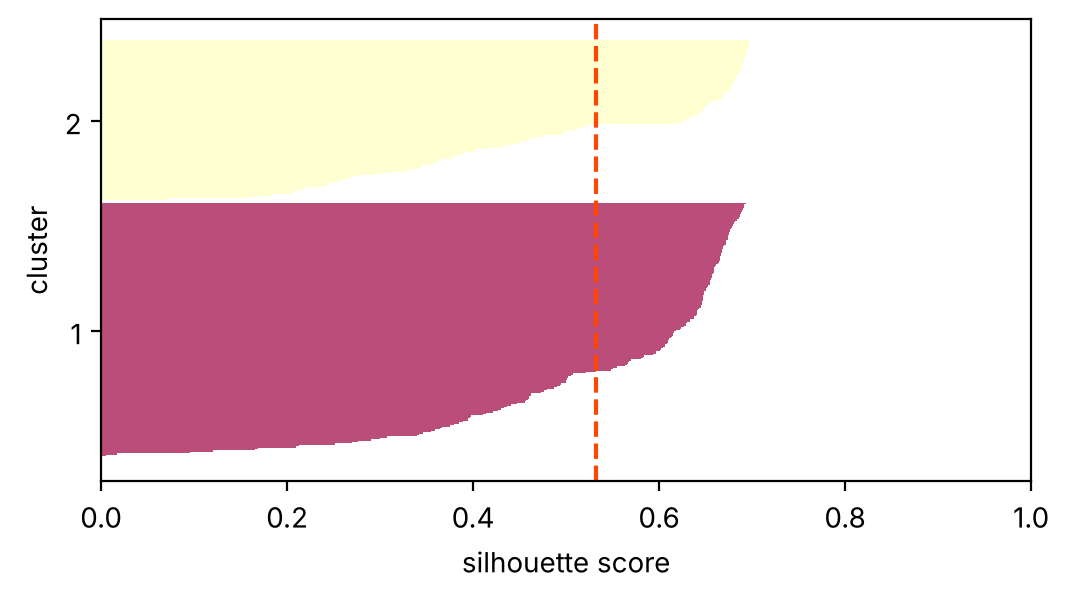

k=3, Silhouette Score: 0.5659


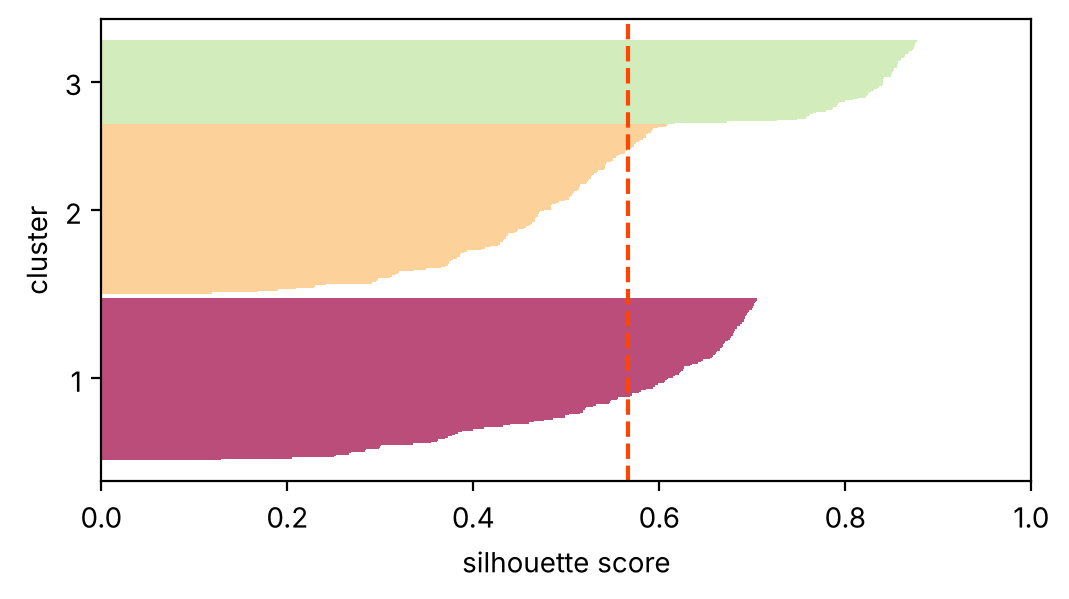

k=4, Silhouette Score: 0.6257


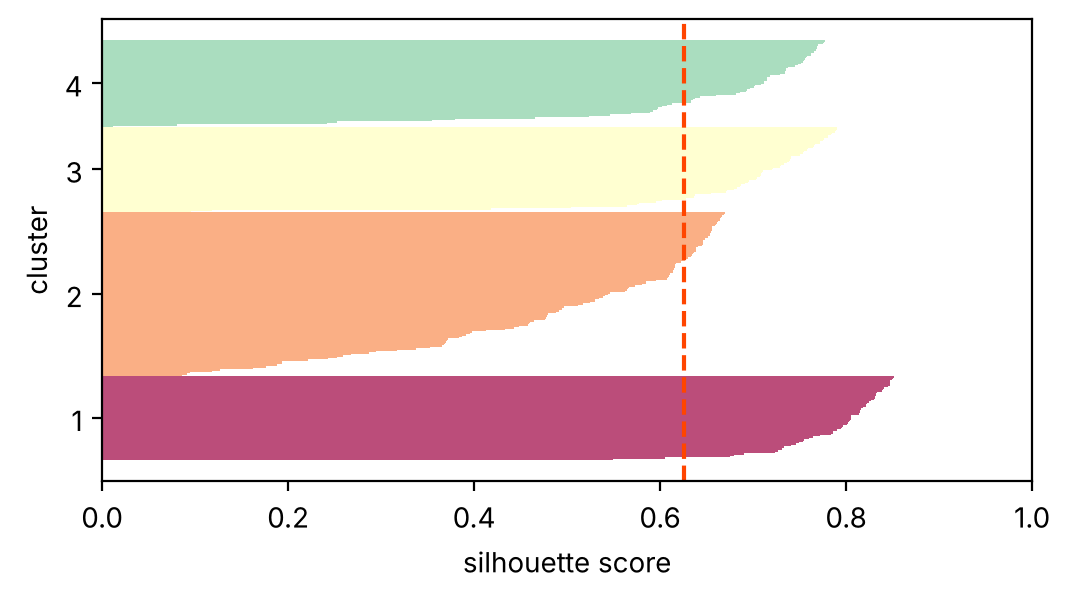

k=5, Silhouette Score: 0.6597


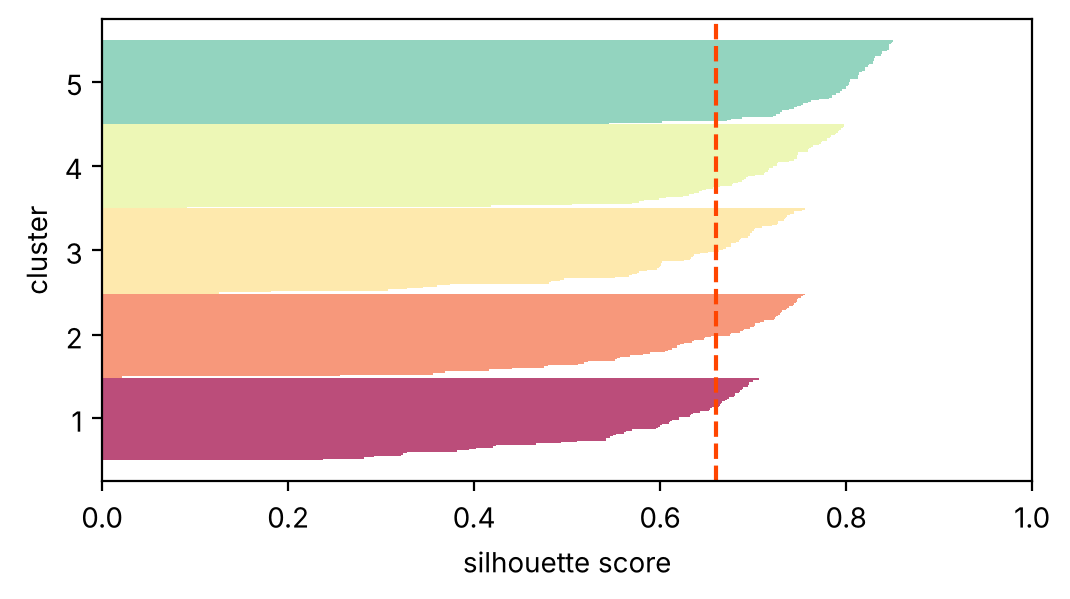

k=6, Silhouette Score: 0.6110


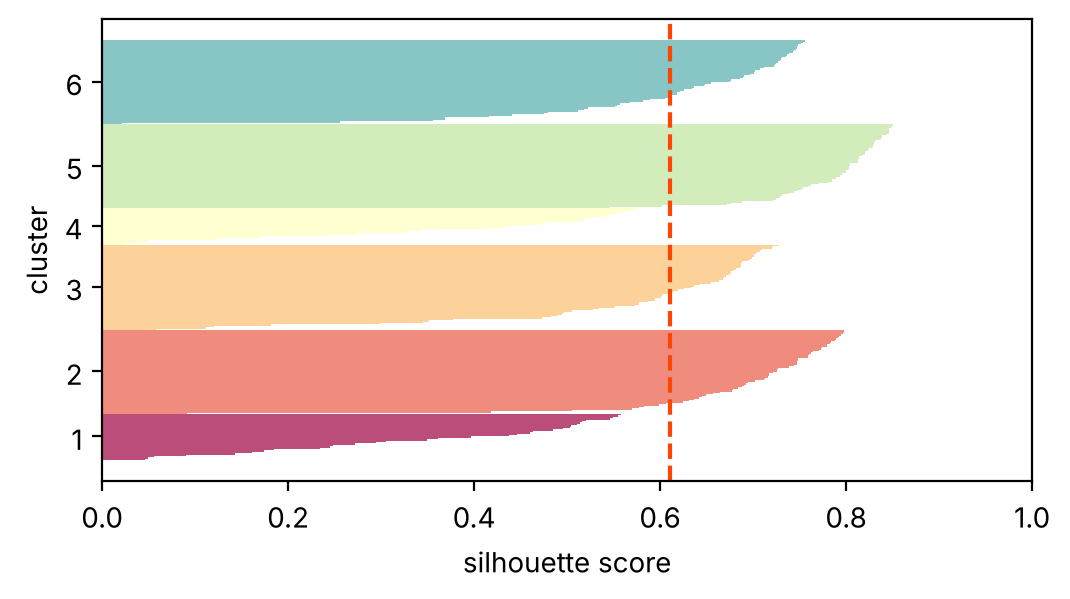

k=7, Silhouette Score: 0.5223


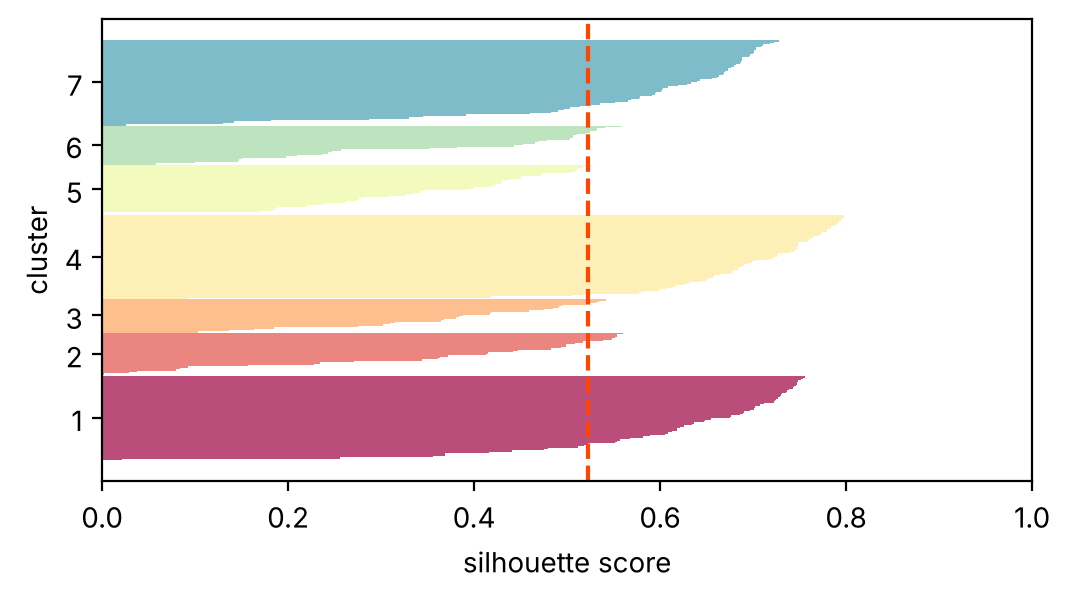

k=8, Silhouette Score: 0.4926


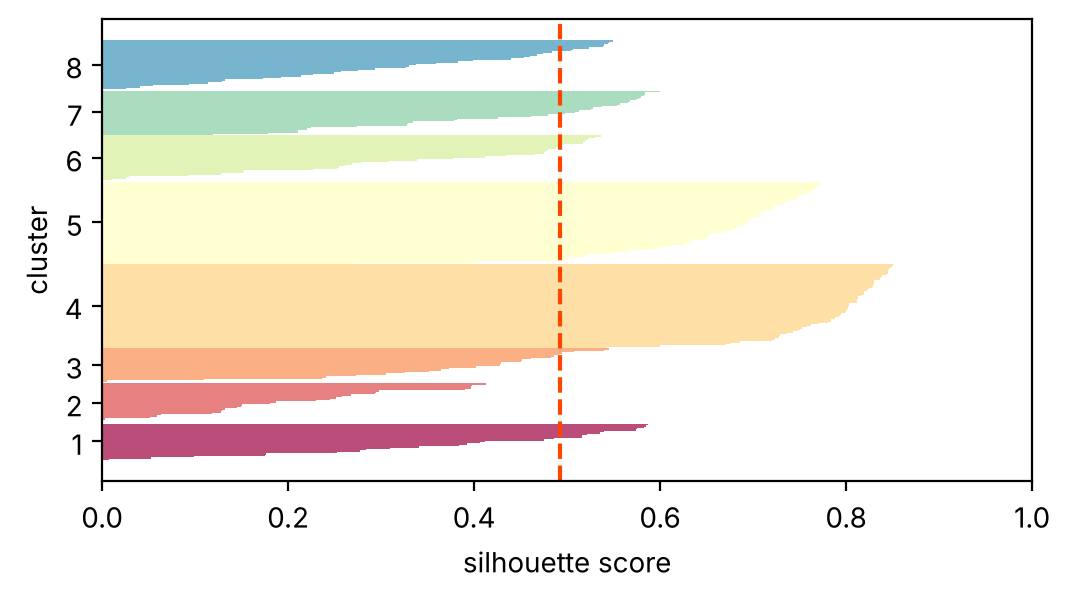

k=9, Silhouette Score: 0.4076


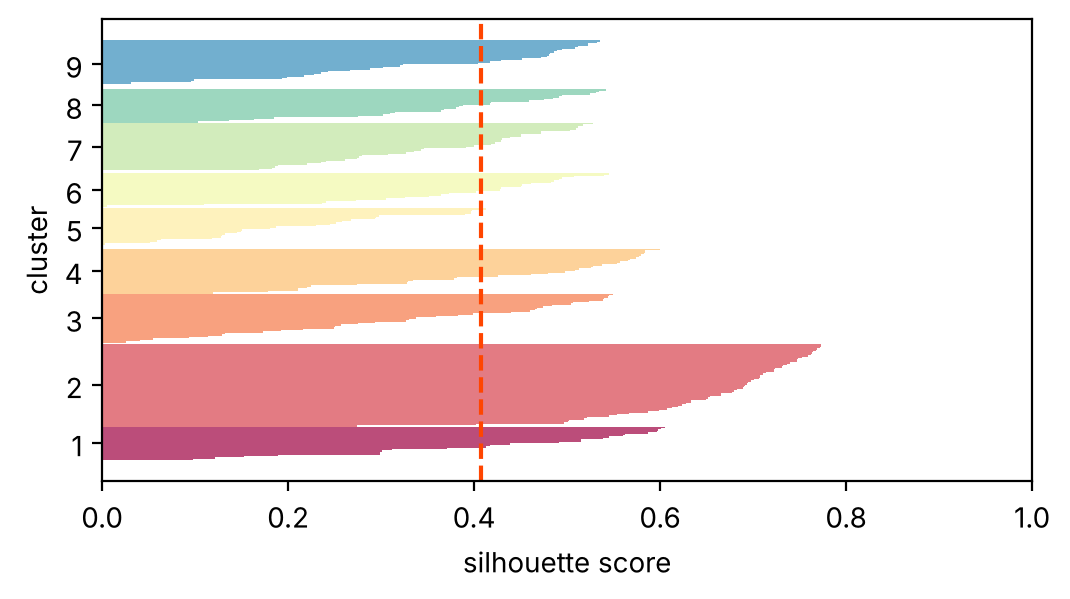

k=10, Silhouette Score: 0.4020


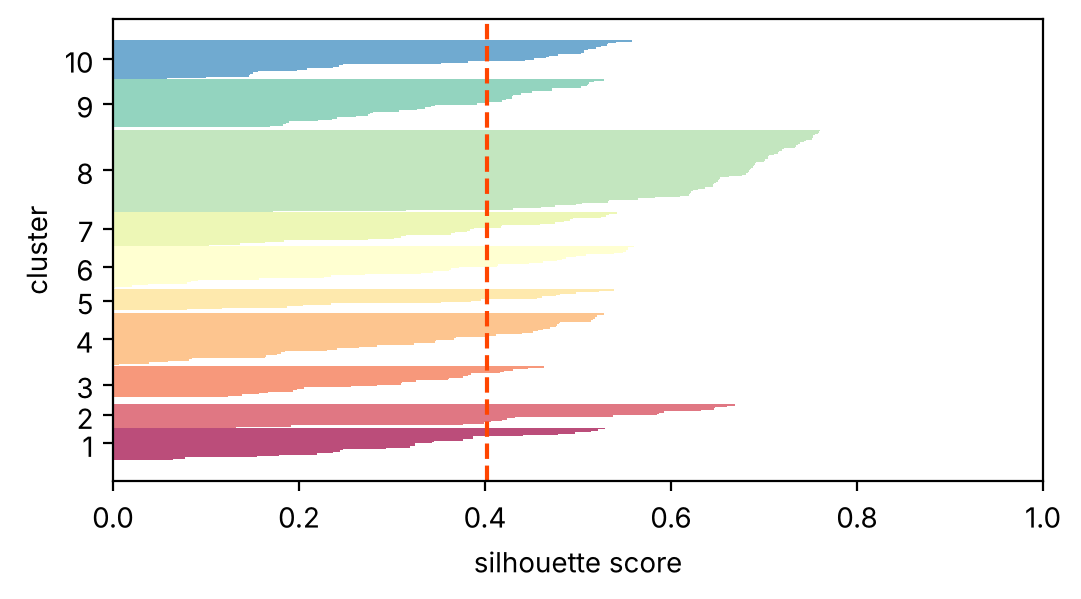

k=11, Silhouette Score: 0.3349


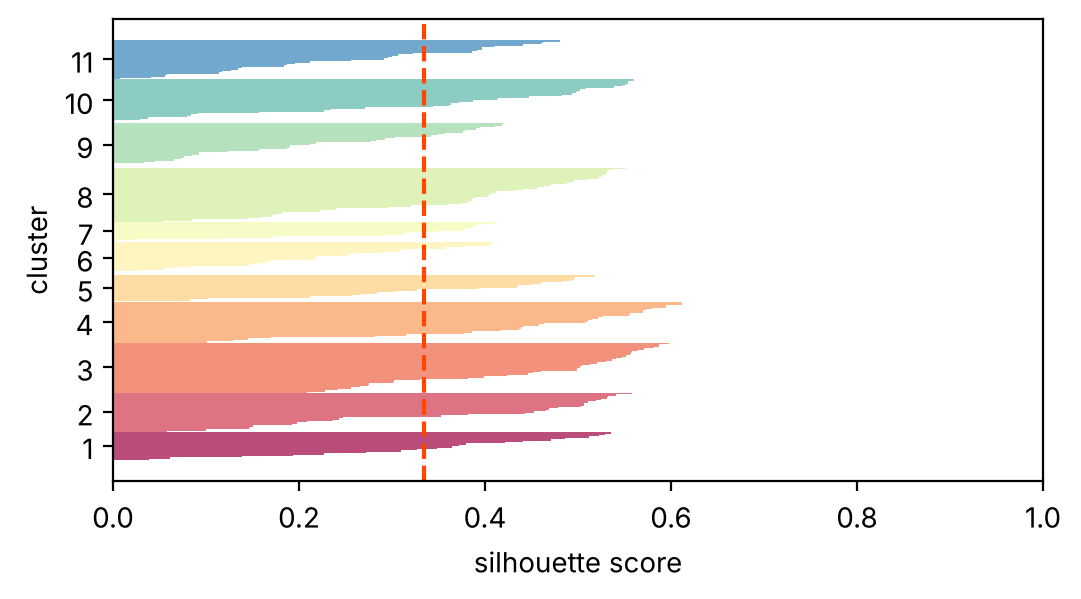

In [7]:
# Import own module for Silhouette plots
from silhouette import *

# Create Silhouette plots for different k's
# Note: range(2,12,1) provides: [2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
for i in range(2,12,1):
    model = KMeans(n_clusters=i, 
                   random_state=42, 
                   init='random')
    model.fit(X)
    print(f'k={i}, Silhouette Score: {silhouette_score(X, model.labels_):.4f}')
    plt.figure(figsize=(6,3))
    show_silhouette(X=X, fitted_model=model)

**Aufgabe 1c – Ergebnis der Silhouetten Analyse (k = 2 bis 11):** Der höchste Silhouette Score ergibt sich bei **k = 5** (0.6597). Bei kleineren k (2 bis 4) sind die Scores tiefer, weil mehrere echte Gruppen zusammengefasst werden. Ab k = 6 sinkt der Score deutlich (bis 0.3349 bei k = 11), weil echte Gruppen unnötig aufgeteilt werden und die Cluster dadurch weniger klar getrennt sind. Die Silhouetten Analyse bestätigt damit das Ergebnis der Ellbogenmethode (k = 5).

## 2.) Image segmentation
<a id='section_2'></a>

### Read the image

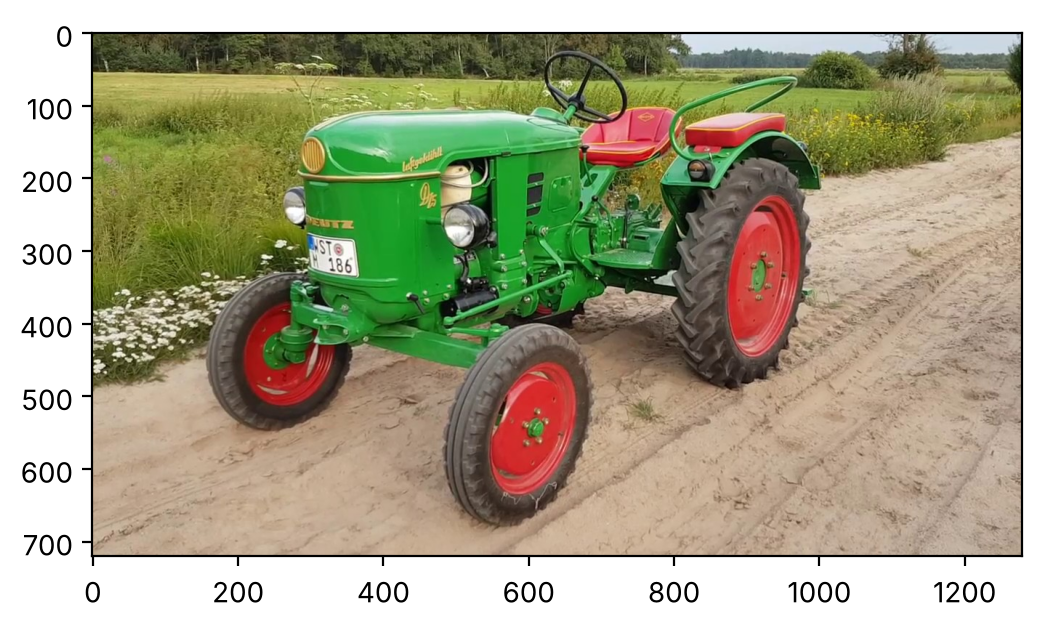

In [8]:
# Read the image
image = cv2.imread('deutz_d15.jpg')
 
# Change the color to RGB (from BGR)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Plot the image
plt.figure(figsize=(6,8))
plt.imshow(image)

### Reshape the image

In [9]:
# Reshaping the image into a 2D array of pixels and RGB colors
pixel_vals = image.reshape((-1,3))
 
# Convert to float
pixel_vals = np.float32(pixel_vals)
pixel_vals

array([[ 50.,  57.,  15.],
       [ 56.,  63.,  21.],
       [ 62.,  69.,  28.],
       ...,
       [174., 156., 136.],
       [168., 150., 130.],
       [166., 148., 128.]], shape=(921600, 3), dtype=float32)

### Elbow method showing the optimal k

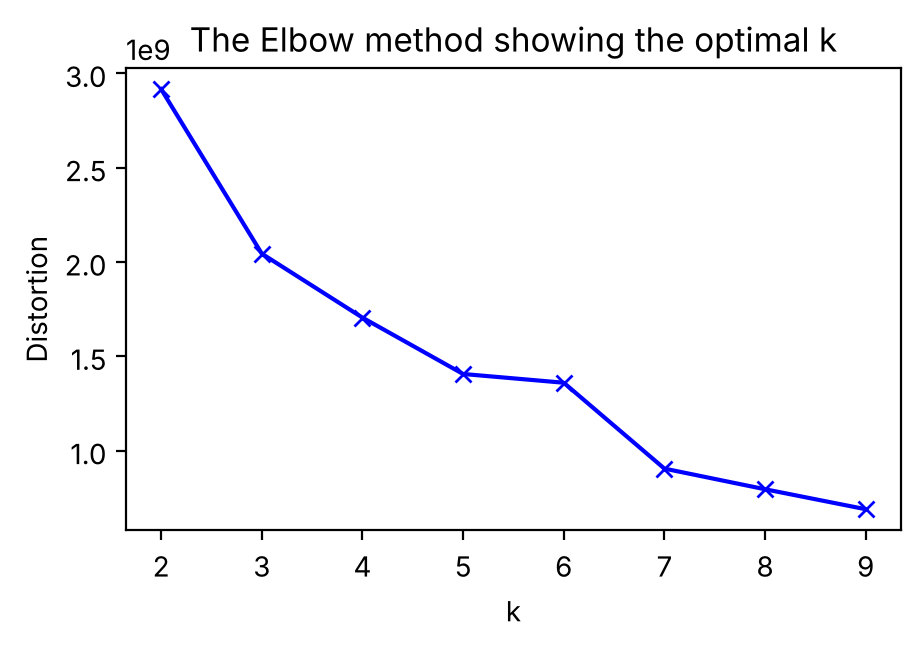

In [10]:
# Sum of squared distances of samples to their closest cluster center
distortions = []

# Range of k's
K = range(2,10,1)

# Loop to find the optimal k
for k in K:
    kmeanModel = KMeans(n_clusters=k)
    kmeanModel.fit(pixel_vals)
    distortions.append(kmeanModel.inertia_)
    
# Elbow plot
plt.figure(figsize=(5,3))
plt.plot(K, distortions, 'bx-')
plt.xlabel('k')
plt.ylabel('Distortion')
plt.title('The Elbow method showing the optimal k')

plt.show()

**Aufgabe 1e – Antwort (eigenes Bild `deutz_d15.jpg`):** Die Kurve im Ellbogendiagramm fällt von k = 2 auf k = 3 am stärksten ab und verläuft danach deutlich flacher. Der erkennbare Knick liegt bei **k = 3**, dieser Wert wird daher als optimal gewählt. Der Ellbogen ist bei Bildern weniger ausgeprägt als im einfachen Beispiel, weil die Farben eines Fotos fliessend ineinander übergehen und keine klar getrennten Gruppen bilden.

### Perform image segmentation

In [11]:
# Number of clusters
k = 3

# Criteria for the segmentation algorithm to stop running
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 0.85)
 
# Perform k-means clustering
retval, labels, centers = cv2.kmeans(pixel_vals, 
                                     k, 
                                     None, 
                                     criteria, 
                                     10, 
                                     cv2.KMEANS_RANDOM_CENTERS)

# Print cluster labels
print('Cluster labels:')
print(labels, '\n')

# Print cluster centroids
print(f'Centroids of {k} clusters')
print(centers)

Cluster labels:
[[1]
 [1]
 [1]
 ...
 [2]
 [2]
 [2]] 

Centroids of 3 clusters
[[137.1859   120.50951   75.26707 ]
 [ 56.950974  88.19345   38.08265 ]
 [191.44807  173.56483  148.15337 ]]


### Change data types and reshape the segmented data for visualization

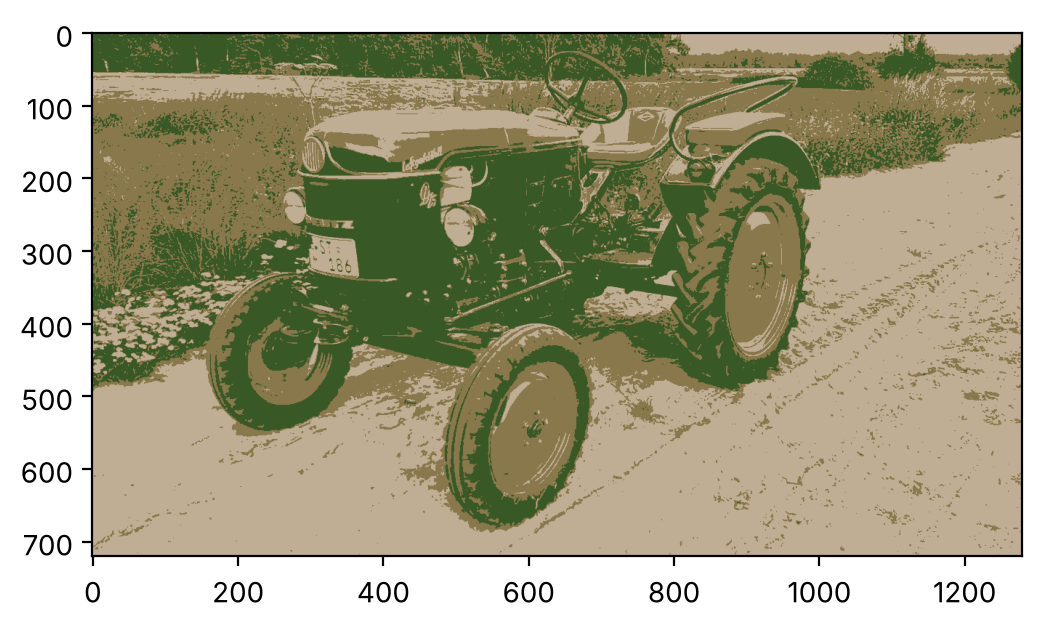

In [12]:
# Convert data into 8-bit values
centers = np.uint8(centers)
segmented_data = centers[labels.flatten()]
 
# Reshape data into the original image dimensions
segmented_image = segmented_data.reshape((image.shape))

# Show result
plt.figure(figsize=(6,8))
plt.imshow(segmented_image)

### Four different image segmentations (Aufgabe 1f)

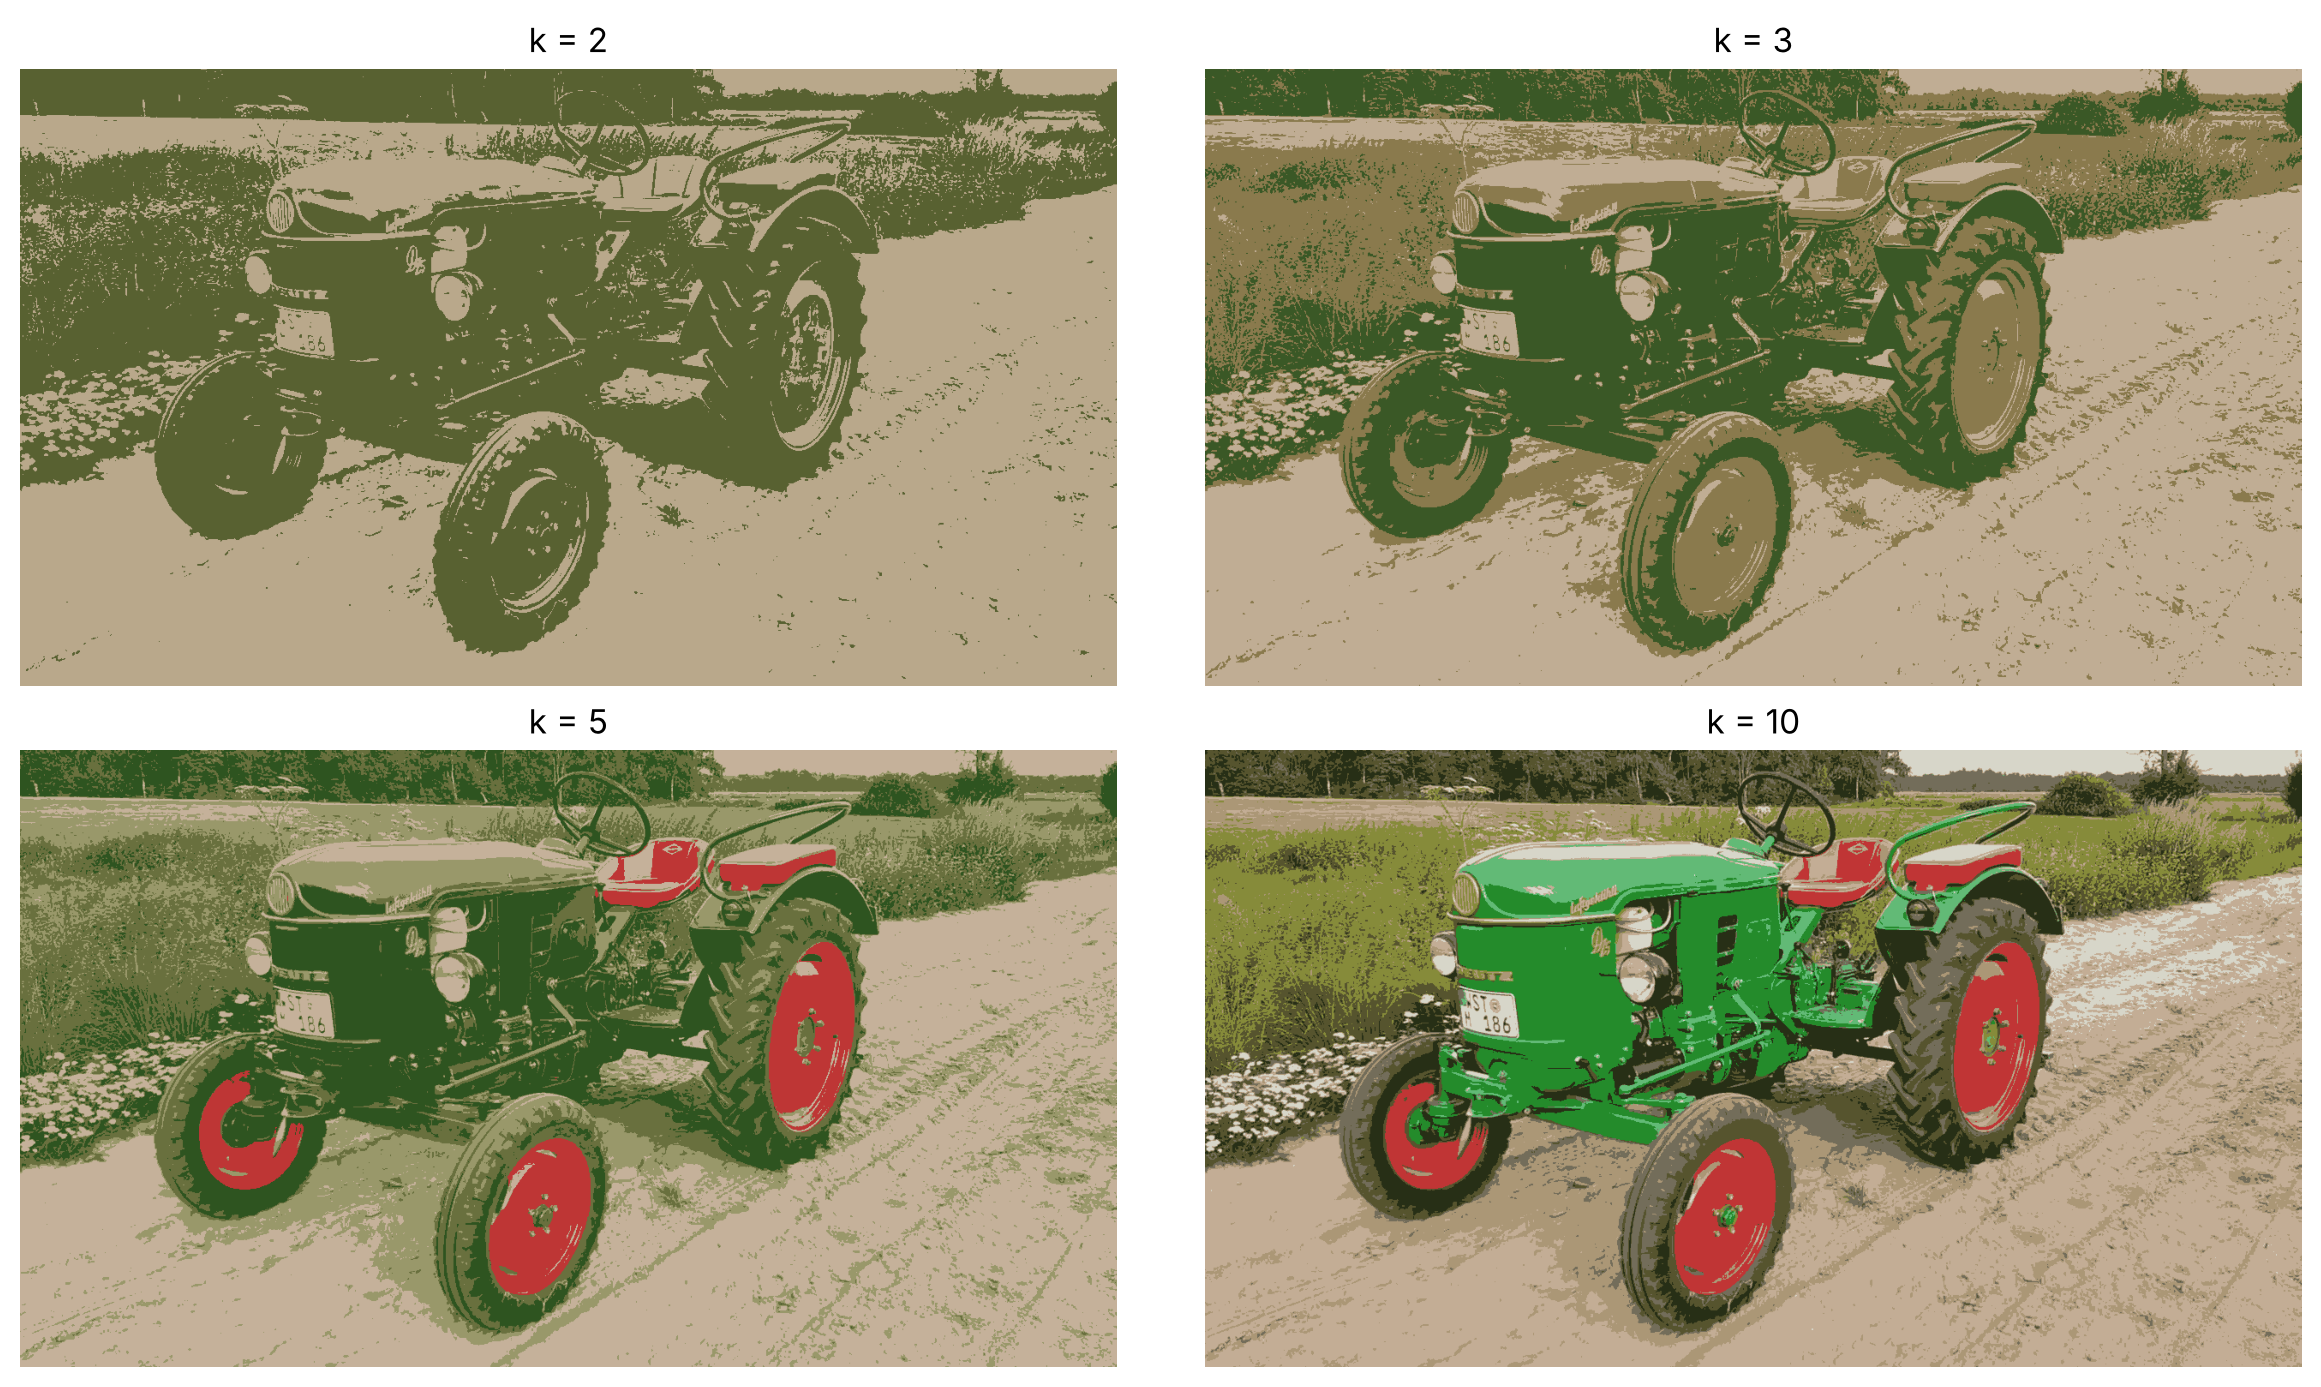

In [13]:
# Four segmentations with different numbers of clusters k
ks = [2, 3, 5, 10]

plt.figure(figsize=(12,7))
for n, k in enumerate(ks, start=1):
    retval, labels, centers = cv2.kmeans(pixel_vals,
                                         k,
                                         None,
                                         criteria,
                                         10,
                                         cv2.KMEANS_RANDOM_CENTERS)
    seg = np.uint8(centers)[labels.flatten()].reshape(image.shape)
    plt.subplot(2, 2, n)
    plt.imshow(seg)
    plt.title(f'k = {k}')
    plt.axis('off')
plt.tight_layout()
plt.show()

**Aufgabe 1f – Beobachtungen:**
- k = 2: Nur zwei Farben (dunkel und hell). Der Traktor ist als Form erkennbar, die Farbinformation fehlt aber komplett.
- k = 3 (optimal laut Ellbogen): Eine zusätzliche Farbe trennt Vegetation, Traktor und Weg grob voneinander.
- k = 5: Die roten Felgen und der Sitz sowie das Grün des Traktors werden eigenständige Segmente.
- k = 10: Das Bild kommt dem Original farblich sehr nahe, auch Himmel, Schatten und Blumen sind getrennt.

Mit steigendem k wird das Bild detailreicher, der Gewinn nimmt aber ab, und die Rechenzeit steigt.

## 3.) 3D point cloud segmentation
- For details see: https://towardsdatascience.com/3d-point-cloud-clustering-tutorial-with-k-means-and-python-c870089f3af8
- Data-Viewer: https://app.flyvast.com/flyvast/app/page-snapshot-viewer.html#/444/9b557b91-8f41-16fa-cd2d-3476a1756611
<a id='section_3'></a>

### Import the data (Airport LIDAR point cloud dataset)

In [14]:
# Import the data
data = "KME_planes.xyz"
x, y, z, illuminance, reflectance, intensity, nb_of_returns = np.loadtxt(data,
                                                                         skiprows=1, 
                                                                         delimiter=';', 
                                                                         unpack=True)
# Array with positions of points
pcd = np.column_stack((x,y,z))

# Mean of z-variable (height above ground)
print(np.mean(z).round(4))

# Subset of the point cloud 
mask = (z > np.mean(z)) & (x <= 320) & (x >= 230)
spatial_query = pcd[mask]
spatial_query.shape

5.2829


(9676, 3)

### 3D plot of the point cloud subset

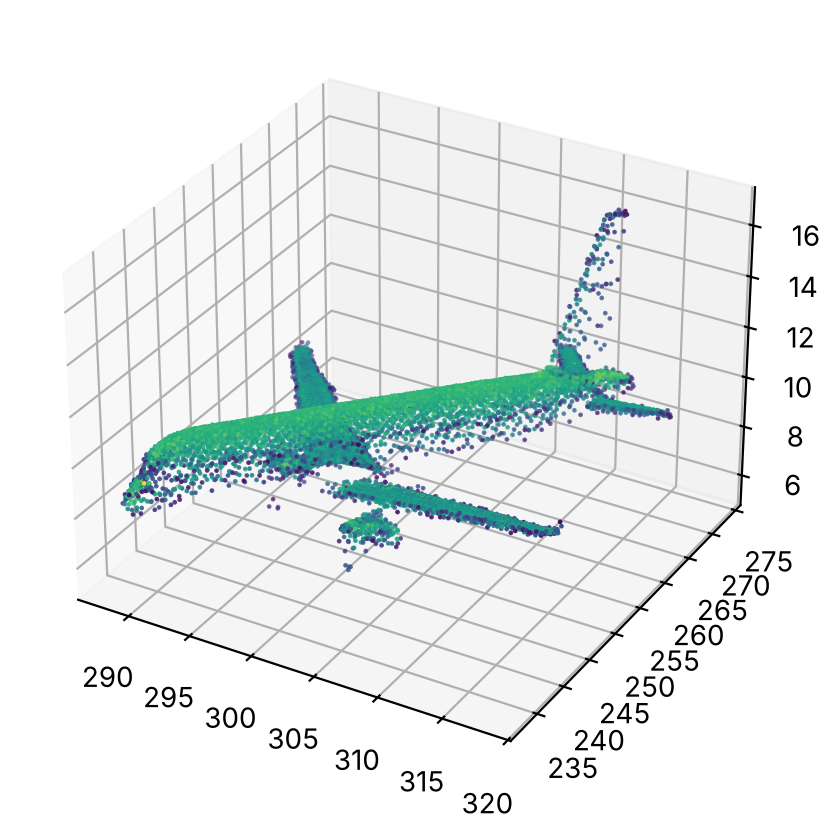

In [15]:
# 3D plot of the subset
plt.figure(figsize=(5,5))
ax = plt.axes(projection ='3d')
ax.scatter(x[mask], y[mask], z[mask], c=intensity[mask], s=0.5)
plt.show()

### 2D plot of the point cloud subset

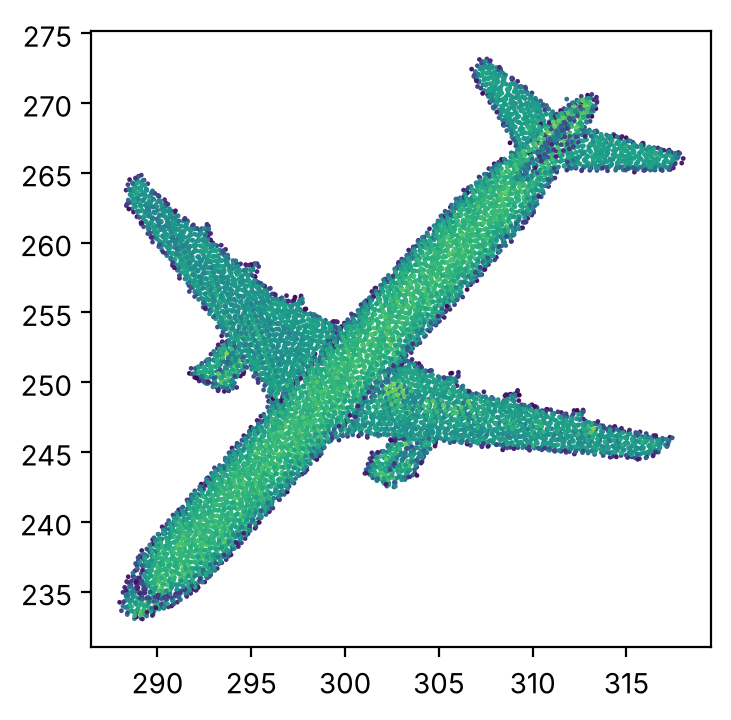

In [16]:
# 2D plot of the subset
plt.figure(figsize=(4,4))
plt.scatter(x[mask], y[mask], c=intensity[mask], s=0.5)
plt.show()

### Elbow method showing the optimal k

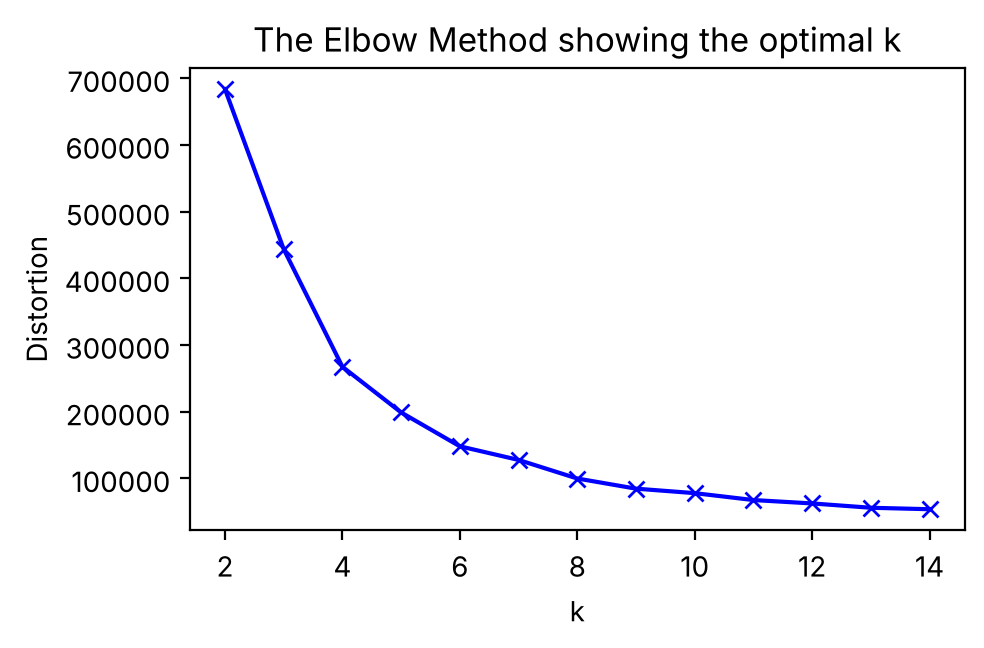

In [17]:
# Sum of squared distances of samples to their closest cluster center
distortions = []

# Range of k's
K = range(2,15,1)

# Loop to find the optimal k
for k in K:
    kmeanModel = KMeans(n_clusters=k)
    kmeanModel.fit(spatial_query)
    distortions.append(kmeanModel.inertia_)
    
# Elbow plot
plt.figure(figsize=(5,3))
plt.plot(K, distortions, 'bx-')
plt.xlabel('k')
plt.ylabel('Distortion')
plt.title('The Elbow Method showing the optimal k')

plt.show()

**Ellbogendiagramm Flughafendaten:** Die Distortion fällt bis k = 4 stark ab und verläuft danach flacher, ein klarer Ellbogen ist nicht erkennbar. Das Beispiel verwendet k = 5.

### Point cloud segmentation based on k-means clustering

In [18]:
# Define number of clusters
k = 5

# Stack with x,y,z values
X2 = np.column_stack((x[mask], y[mask], z[mask]))

# Perform k-means clustering
kmeans_aerpl = KMeans(n_clusters=k, random_state=42).fit(X2)

### 2D plot of the segmented point cloud

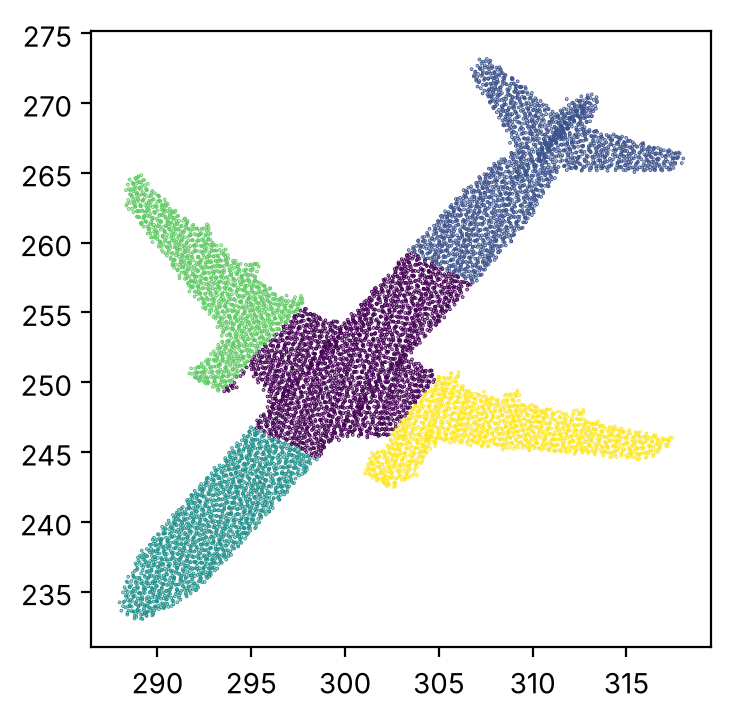

In [19]:
# 2D plot of image segmentation
plt.figure(figsize=(4,4))
plt.scatter(x[mask], y[mask], c=kmeans_aerpl.labels_, s = 0.1)
plt.show()

### 3D plot of the segmented point cloud

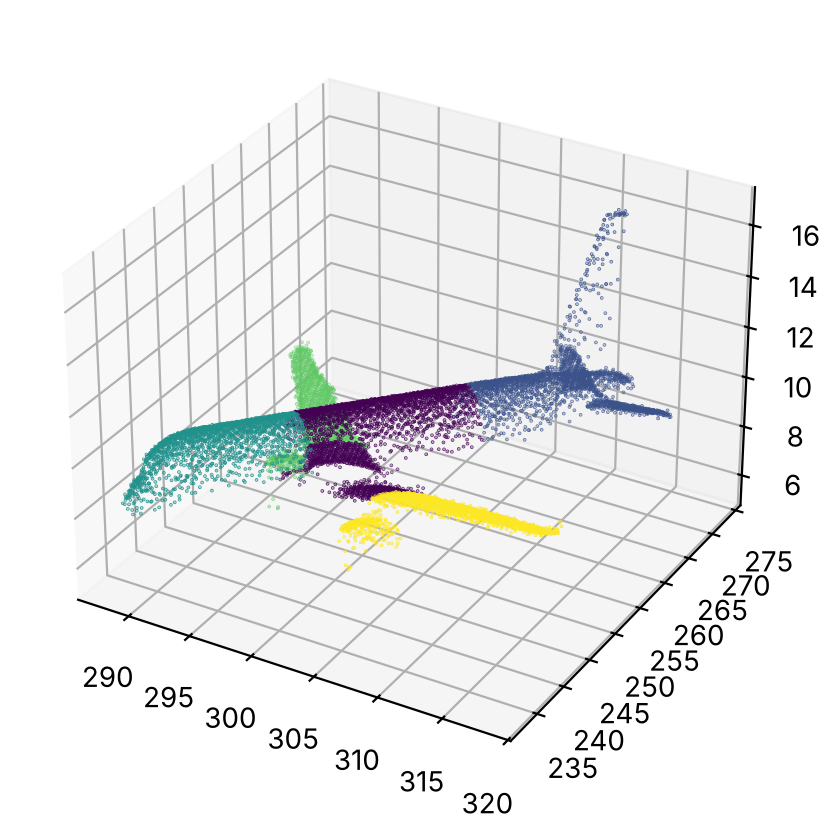

In [20]:
# 3D plot of image segmentation
plt.figure(figsize=(5,5))
ax = plt.axes(projection ='3d')
ax.scatter(x[mask], y[mask], z[mask], c=kmeans_aerpl.labels_, s=0.1)
plt.show()

### Calculate the Silhouette Score

In [21]:
print(f'Silhouette Score: {silhouette_score(X2, kmeans_aerpl.labels_):.4f}')

Silhouette Score: 0.4704


### Different values of k for the 3D point cloud segmentation (Aufgabe 1h)

k=2, Silhouette Score (sample of 10000 points): 0.4737


k=3, Silhouette Score (sample of 10000 points): 0.4405


k=8, Silhouette Score (sample of 10000 points): 0.4194


k=12, Silhouette Score (sample of 10000 points): 0.4333


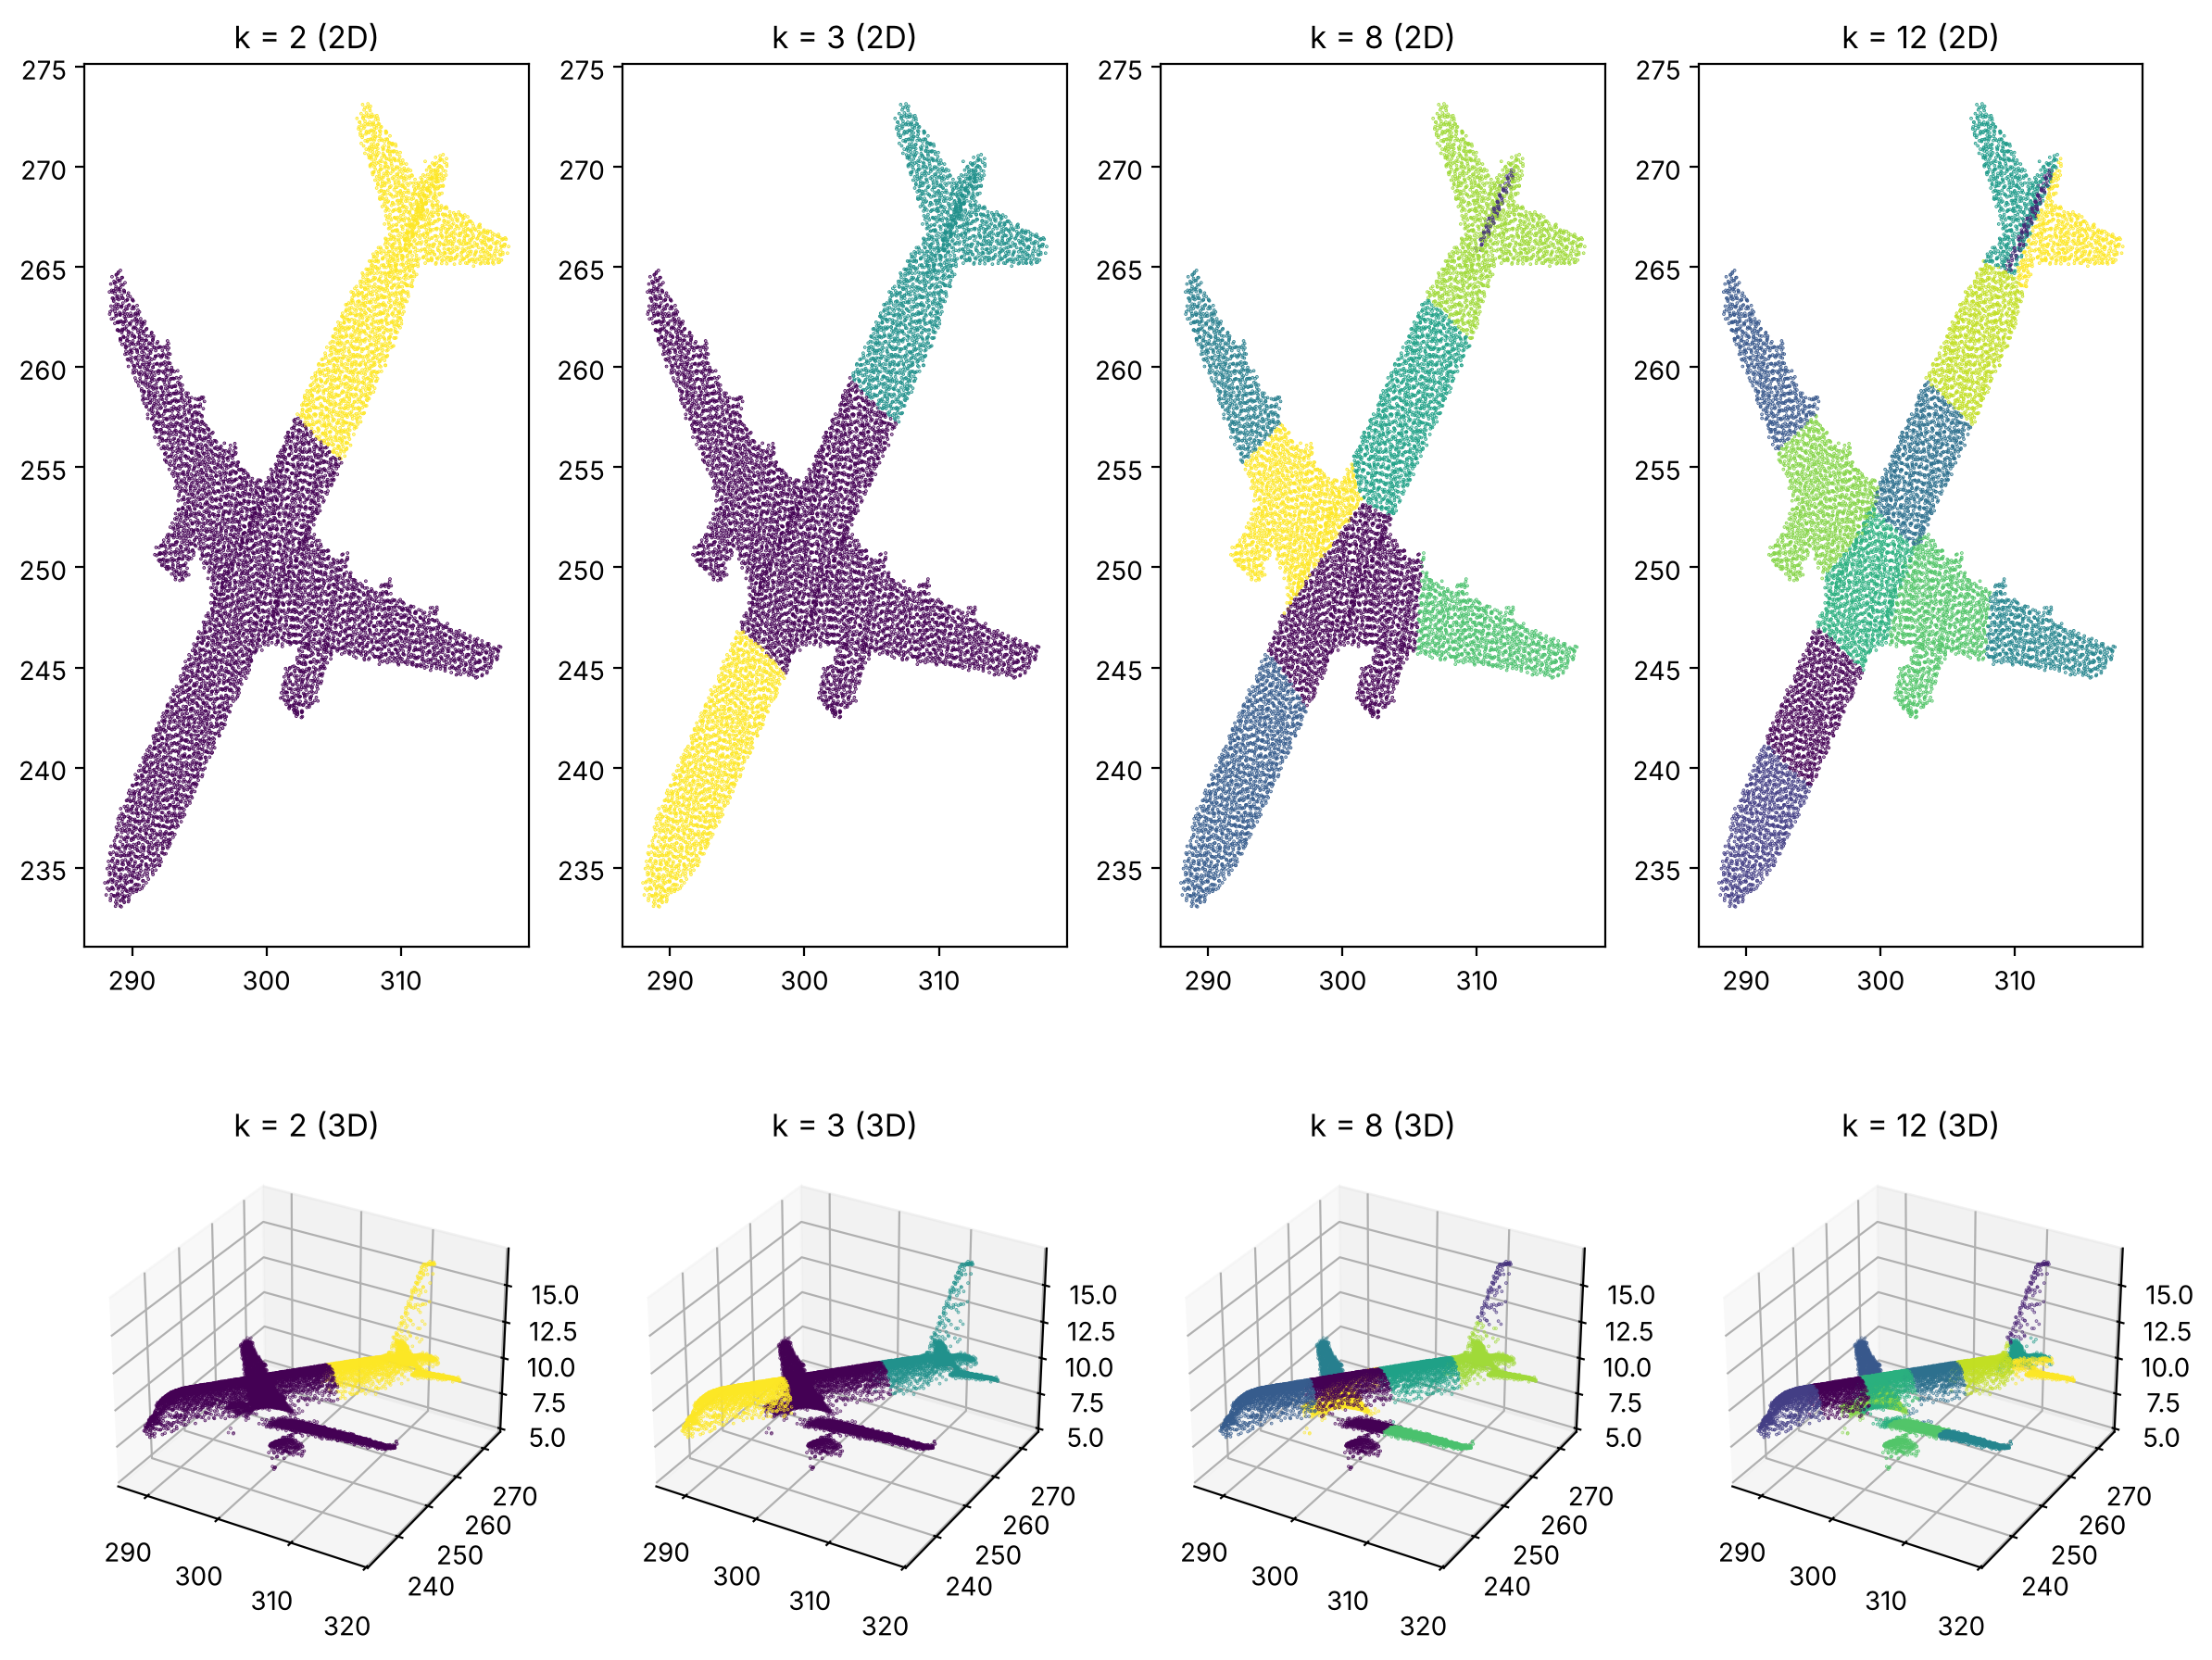

In [22]:
# Different values of k
ks = [2, 3, 8, 12]

fig = plt.figure(figsize=(12,10))
for n, k in enumerate(ks, start=1):
    km = KMeans(n_clusters=k, random_state=42).fit(X2)
    sil = silhouette_score(X2, km.labels_, sample_size=10000, random_state=42)
    print(f'k={k}, Silhouette Score (sample of 10000 points): {sil:.4f}')

    # 2D plot (top view)
    ax = fig.add_subplot(2, 4, n)
    ax.scatter(x[mask], y[mask], c=km.labels_, s=0.1)
    ax.set_title(f'k = {k} (2D)')

    # 3D plot
    ax = fig.add_subplot(2, 4, n + 4, projection='3d')
    ax.scatter(x[mask], y[mask], z[mask], c=km.labels_, s=0.1)
    ax.set_title(f'k = {k} (3D)')
plt.tight_layout()
plt.show()

**Aufgabe 1h – Beobachtungen bei verschiedenen Werten von k:**
- k = 2: Das Flugzeug wird grob in zwei Teile getrennt (hinterer Rumpf mit Heck gegen den Rest mit Flügeln und Nase).
- k = 3: Zusätzlich wird die Nase abgetrennt. Flügel und Rumpfmitte bleiben ein gemeinsames Cluster.
- k = 8: Erste sinnvolle Bauteile entstehen: die beiden Flügel, das Seitenleitwerk, Nase, Rumpfabschnitte und die Triebwerke bilden je eigene Cluster.
- k = 12: Rumpf und Flügel werden in schmale Abschnitte zerlegt, die Segmentierung wird feiner.

Insgesamt teilt k-means die Punktwolke in räumlich kompakte, etwa gleich grosse Bereiche auf. Mit mehr Clustern wird die Einteilung detaillierter, die Cluster entsprechen aber nicht immer echten Bauteilen (Rumpf wird quer in Scheiben geschnitten). Die Silhouette Scores sind mit 0.42 bis 0.47 in allen Fällen mittelmässig und ändern sich kaum, da die Punktwolke ein zusammenhängendes Objekt ohne natürliche Cluster ist.

## 4.) Finding clusters in the apartment data
<a id='section_4'></a>

### Import the apartment data

In [23]:
# Define columns for import
columns = [ 'web-scraper-order',
            'address_raw',
            'rooms',
            'area',
            'luxurious',
            'price',
            'price_per_m2',
            'lat',
            'lon',
            'bfs_number',
            'bfs_name',
            'pop',
            'pop_dens',
            'frg_pct',
            'emp',
            'mean_taxable_income',
            'dist_supermarket']

# Read and select variables
df_orig = pd.read_csv("apartments_data_enriched_cleaned.csv", sep=";", encoding='utf-8')[columns]

# Rename variable 'web-scraper-order' to 'apmt_id'
df_orig = df_orig.rename(columns={'web-scraper-order': 'id'})

# Remove missing values
df = df_orig.dropna()
df.head(5)

# Remove duplicates
df = df.drop_duplicates()

# Remove some 'extreme' values
df = df.loc[(df['price'] >= 1000) & 
            (df['price'] <= 5000)]

print(df.shape)
df.head(5)

(722, 17)


,id,address_raw,rooms,area,luxurious,price,price_per_m2,lat,lon,bfs_number,bfs_name,pop,pop_dens,frg_pct,emp,mean_taxable_income,dist_supermarket
0,1693998201-1,"Neuhusstrasse 6, 8630 Rüti ZH, ZH",3.0,49,0,1441,29.41,47.252171,8.845797,118,Rüti (ZH),12286,1221.272366,24.841283,5053,65362.04268,645.652248
1,1693998233-172,"Widacherstrasse 5, 8630 Rüti ZH, ZH",3.0,111,0,2600,23.42,47.252087,8.854919,118,Rüti (ZH),12286,1221.272366,24.841283,5053,65362.04268,265.102153
2,1693998256-331,"Widenweg 14, 8630 Rüti ZH, ZH",3.0,58,0,1490,25.69,47.253670,8.853993,118,Rüti (ZH),12286,1221.272366,24.841283,5053,65362.04268,94.401821
3,1693998265-381,"Rain 1, 8630 Rüti ZH, ZH",4.0,118,0,3240,27.46,47.259834,8.851705,118,Rüti (ZH),12286,1221.272366,24.841283,5053,65362.04268,106.660970
4,1693998276-419,"Bachtelstrasse 24b, 8630 Rüti ZH, ZH",3.0,66,0,1450,21.97,47.266113,8.866872,118,Rüti (ZH),12286,1221.272366,24.841283,5053,65362.04268,974.844209


### Subset of the apartment data frame for k-means clustering

In [24]:
# Define a subset of the data frame for k-means clustering
X3 = df[['rooms',
         'area',
         'price_per_m2',
         'lat',
         'lon',
         'pop_dens',
         'mean_taxable_income']]

### Elbow method showing the optimal k

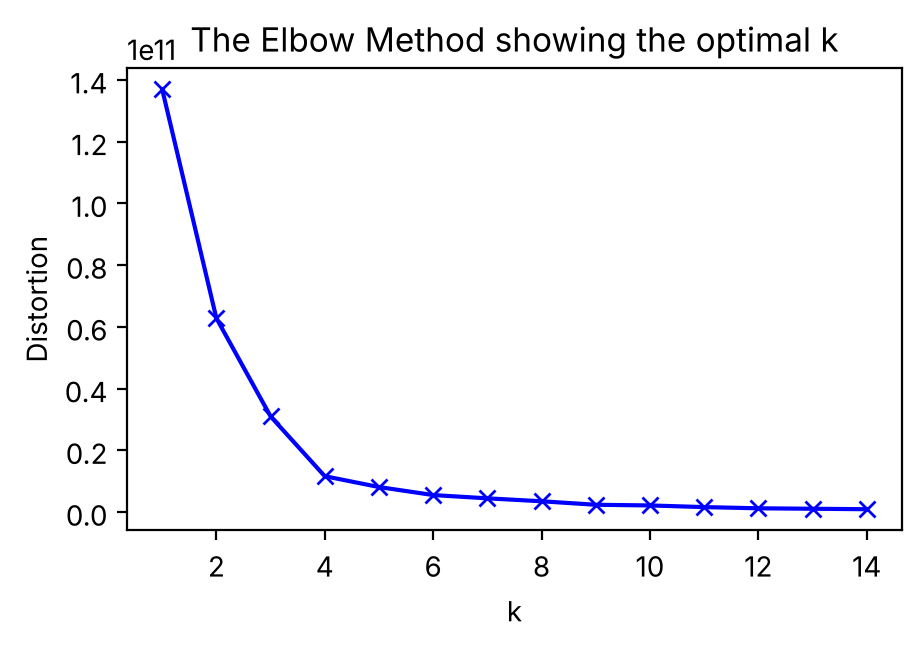

In [25]:
# Sum of squared distances of samples to their closest cluster center
distortions = []

# Range of k's
K = range(1,15)

# Loop to find the optimal k
for k in K:
    kmeanModel = KMeans(n_clusters=k)
    kmeanModel.fit(X3)
    distortions.append(kmeanModel.inertia_)
    
# Elbow plot
plt.figure(figsize=(5,3))
plt.plot(K, distortions, 'bx-')
plt.xlabel('k')
plt.ylabel('Distortion')
plt.title('The Elbow Method showing the optimal k')

plt.show()

**Aufgabe 2c – Antwort:** Beim erweiterten Dataframe X3 (rooms, area, price_per_m2, lat, lon, pop_dens, mean_taxable_income) fällt die Distortion bis k = 4 stark ab und verläuft danach sehr flach. Der optimale Wert laut Ellbogenmethode ist **k = 4**.

### Perform k-means clustering on the apartment data

In [26]:
# Number of clusters
k = 4

# Perform k-means clustering
kmeans_apmts = KMeans(n_clusters=k, random_state=42).fit(X3)

# Add the clusters to data frame
X3['cluster'] = kmeans_apmts.predict(X3)

# Show number of apartments per cluster
X3['cluster'].value_counts().sort_values(ascending=False)

cluster
2    391
0    286
1     37
3      8
Name: count, dtype: int64

### Plot the apartment clusters

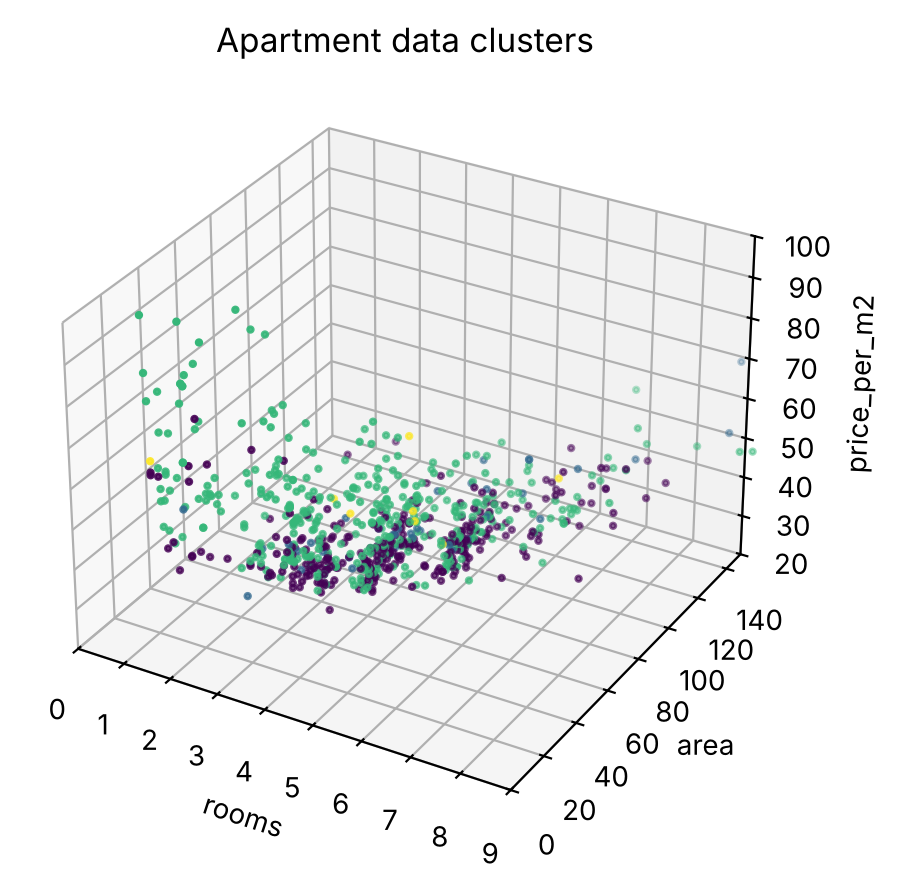

In [27]:
fig = plt.figure(figsize=(6,5))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(df['rooms'], df['area'], df['price_per_m2'], c=kmeans_apmts.labels_, s=4)

# Set title and axes labels
ax.set_title('Apartment data clusters', fontsize=12)
ax.set_xlabel('rooms', fontsize=10)
ax.set_ylabel('area', fontsize=10)
ax.set_zlabel('price_per_m2', fontsize=10)

# Set axes range
ax.set_xlim([0,9])
ax.set_ylim([0,150])
ax.set_zlim([20,100])

plt.show()

### Attributes of the k-means model 'kmeans_apmts' (Aufgabe 2e)

In [28]:
print(kmeans_apmts.labels_, '\n')
print(kmeans_apmts.inertia_, '\n')
print(kmeans_apmts.cluster_centers_, '\n')
print(kmeans_apmts.feature_names_in_)

[0 0 0 0 0 0 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 2 2 2 2 2 2 2 2 2 2
 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 2 2 2 2 3 3 2 0 0 0 0 0 0 0 0 0 0 2
 2 2 2 2 2 2 2 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 2 2 2 2 2 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 0 0 2 2 2 2 2 2 2 2 0 0 0 2 2 2 2
 2 2 0 0 0 0 0 1 2 2 1 0 0 3 2 2 2 2 2 0 1 1 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 2 

**Aufgabe 2f – Bedeutung der Ausgabe** (gemäss sklearn.cluster.KMeans Dokumentation, "Attributes"):
- `labels_`: Cluster Zugehörigkeit jeder Wohnung (Werte 0 bis 3). Die Reihenfolge entspricht den Zeilen von X3.
- `inertia_`: Summe der quadrierten Distanzen aller Wohnungen zum jeweils nächsten Cluster Zentrum (within-cluster sum-of-squares, WCSS). Hier ca. 1.16e10. Je kleiner der Wert, desto kompakter die Cluster. Der Wert ist gross, weil die Variablen nicht standardisiert sind (v. a. `mean_taxable_income` hat sehr grosse Zahlenwerte).
- `cluster_centers_`: Koordinaten der 4 Cluster Zentren (Zeile pro Cluster, Spalte pro Variable). Die Spalten entsprechen der Reihenfolge in `feature_names_in_`.
- `feature_names_in_`: Namen der Variablen, mit denen das Modell trainiert wurde (rooms, area, price_per_m2, lat, lon, pop_dens, mean_taxable_income).

### Calculate the Silhouette Score

In [29]:
# Silhouette Score of 'kmeans_apmts' (without the added 'cluster' column)
X3_features = X3.drop(columns='cluster')
print(f'k={kmeans_apmts.n_clusters}, Silhouette Score: {silhouette_score(X3_features, kmeans_apmts.labels_):.4f}')

k=4, Silhouette Score: 0.6870


### Silhouette Score for different values of k (Aufgabe 2g)

k=2, Silhouette Score: 0.7938
k=3, Silhouette Score: 0.6446
k=4, Silhouette Score: 0.6870
k=5, Silhouette Score: 0.6847
k=6, Silhouette Score: 0.6391
k=7, Silhouette Score: 0.6758
k=8, Silhouette Score: 0.5948
k=9, Silhouette Score: 0.6742
k=10, Silhouette Score: 0.6799
k=11, Silhouette Score: 0.7028
k=12, Silhouette Score: 0.7063
k=13, Silhouette Score: 0.7234
k=14, Silhouette Score: 0.7016

Highest Silhouette Score: k=2 (0.7938)


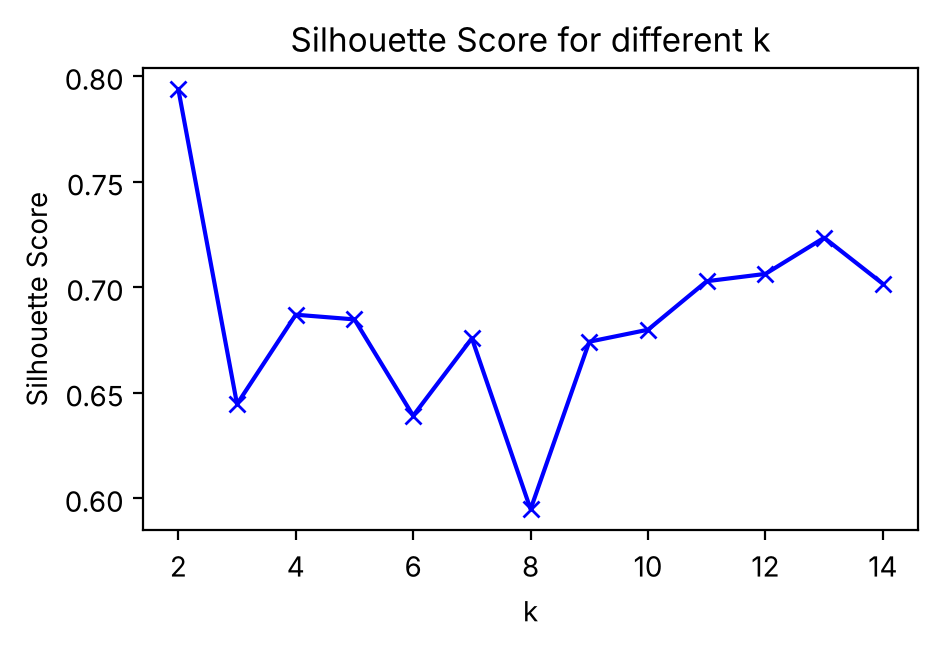

In [30]:
# Silhouette Score for different values of k (same features as in 'kmeans_apmts')
sil_scores = {}
for k in range(2, 15):
    model = KMeans(n_clusters=k, random_state=42).fit(X3_features)
    sil_scores[k] = silhouette_score(X3_features, model.labels_)
    print(f'k={k}, Silhouette Score: {sil_scores[k]:.4f}')

best_k = max(sil_scores, key=sil_scores.get)
print(f'\nHighest Silhouette Score: k={best_k} ({sil_scores[best_k]:.4f})')

plt.figure(figsize=(5,3))
plt.plot(list(sil_scores.keys()), list(sil_scores.values()), 'bx-')
plt.xlabel('k')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score for different k')
plt.show()

**Aufgabe 2g – Antwort:** Der Silhouette Score von `kmeans_apmts` (k = 4) beträgt 0.6870. Der höchste Silhouette Score ergibt sich aber bei **k = 2** (0.7938). Der durch die Ellbogenmethode vorgeschlagene Wert (k = 4) ist damit **nicht konsistent** mit dem Wert für k mit dem höchsten Silhouette Score (k = 2).

Mögliche Erklärung: Die Variablen wurden nicht standardisiert. Die Distanzen werden daher fast nur durch `mean_taxable_income` und `pop_dens` bestimmt, und k = 2 trennt diese grossen Unterschiede am saubersten. Mit k = 4 wird ein sinnvoller Kompromiss zwischen Detailgrad und Trennschärfe erreicht.

### Jupyter notebook --footer info-- (please always provide this at the end of each submitted notebook)

In [31]:
import os
import platform
import socket
from platform import python_version
from datetime import datetime

print('-----------------------------------')
print(os.name.upper())
print(platform.system(), '|', platform.release())
print('Datetime:', datetime.now().strftime("%Y-%m-%d %H:%M:%S"))
print('Python Version:', python_version())
print('-----------------------------------')

-----------------------------------
POSIX
Linux | 6.18.44-fc-v653
Datetime: 2026-11-19 17:30:05
Python Version: 3.13.18
-----------------------------------
